In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [37]:
data = {'cgpa': [6.82, 6.36, 5.39, 5.50, 6.39, 9.13, 7.17, 7.12], 'iq': [118, 125, 99, 106, 148, 148, 147, 72],
        'is_placed': [0, 1, 1, 1, 0, 1, 1, 0]}

In [38]:
df = pd.DataFrame(data)

In [39]:
df

,cgpa,iq,is_placed
0,6.82,118,0
1,6.36,125,1
2,5.39,99,1
3,5.50,106,1
4,6.39,148,0
5,9.13,148,1
6,7.17,147,1
7,7.12,72,0


In [40]:
df['f0(x)'] = np.log((df[df['is_placed'] == 1].shape[0]) / (df[df['is_placed'] == 0].shape[0]))

In [41]:
df

,cgpa,iq,is_placed,f0(x)
0,6.82,118,0,0.510826
1,6.36,125,1,0.510826
2,5.39,99,1,0.510826
3,5.50,106,1,0.510826
4,6.39,148,0,0.510826
5,9.13,148,1,0.510826
6,7.17,147,1,0.510826
7,7.12,72,0,0.510826


In [42]:
df['prob0'] = 1/ (1 + np.exp(-df['f0(x)'])) 

In [43]:
df

,cgpa,iq,is_placed,f0(x),prob0
0,6.82,118,0,0.510826,0.625
1,6.36,125,1,0.510826,0.625
2,5.39,99,1,0.510826,0.625
3,5.50,106,1,0.510826,0.625
4,6.39,148,0,0.510826,0.625
5,9.13,148,1,0.510826,0.625
6,7.17,147,1,0.510826,0.625
7,7.12,72,0,0.510826,0.625


In [44]:
df['r1'] = df['is_placed'] - df['prob0']

In [45]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1
0,6.82,118,0,0.510826,0.625,-0.625
1,6.36,125,1,0.510826,0.625,0.375
2,5.39,99,1,0.510826,0.625,0.375
3,5.50,106,1,0.510826,0.625,0.375
4,6.39,148,0,0.510826,0.625,-0.625
5,9.13,148,1,0.510826,0.625,0.375
6,7.17,147,1,0.510826,0.625,0.375
7,7.12,72,0,0.510826,0.625,-0.625


In [46]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [47]:
dt1 = DecisionTreeRegressor(max_leaf_nodes= 3)

In [48]:
dt1.fit(df.iloc[:, :2], df.iloc[:, -1])

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,3
,min_impurity_decrease,0.0
,ccp_alpha,0.0


[Text(0.4, 0.8333333333333334, 'x[0] <= 6.375\nsquared_error = 0.234\nsamples = 8\nvalue = 0.0'),
 Text(0.2, 0.5, 'squared_error = 0.0\nsamples = 3\nvalue = 0.375'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[0] <= 7.145\nsquared_error = 0.24\nsamples = 5\nvalue = -0.225'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'squared_error = 0.0\nsamples = 3\nvalue = -0.625'),
 Text(0.8, 0.16666666666666666, 'squared_error = 0.0\nsamples = 2\nvalue = 0.375')]

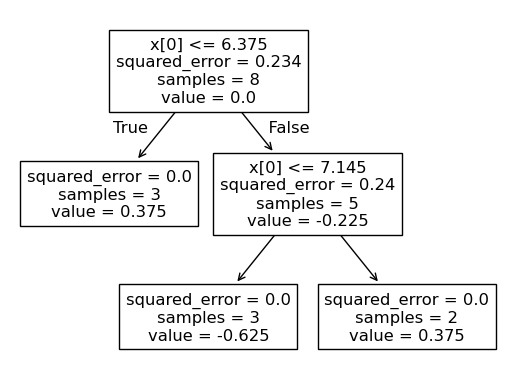

In [61]:
plot_tree(dt1)

In [62]:
dt1.apply(df.iloc[:, :2])

array([3, 1, 1, 1, 3, 4, 4, 3])

In [63]:
df['leaf_nodes_1'] = dt1.apply(df.iloc[:, :2])

In [64]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1
0,6.82,118,0,0.510826,0.625,-0.625,3
1,6.36,125,1,0.510826,0.625,0.375,1
2,5.39,99,1,0.510826,0.625,0.375,1
3,5.50,106,1,0.510826,0.625,0.375,1
4,6.39,148,0,0.510826,0.625,-0.625,3
5,9.13,148,1,0.510826,0.625,0.375,4
6,7.17,147,1,0.510826,0.625,0.375,4
7,7.12,72,0,0.510826,0.625,-0.625,3


In [76]:
df['denominator'] = df['prob0'] * (1- df['prob0'])

In [77]:
leaf_stats = df.groupby('leaf_nodes_1').agg(sum_residual = ('r1', 'sum'), sum_denomiantor = ('denominator', 'sum'))

In [78]:
leaf_stats['gamma1'] = leaf_stats['sum_residual'] / leaf_stats['sum_denomiantor']

In [80]:
df['gamma1'] = df['leaf_nodes_1'].map(leaf_stats['gamma1'])

In [81]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667


In [82]:
df['f1(x)'] = df['f0(x)'] + df['gamma1']

In [83]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x)
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841


In [84]:
df['prob1'] = 1/ (1 + np.exp(-df['f1(x)']))

In [85]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787


In [86]:
df['r2'] = df['is_placed'] - df['prob1']

In [87]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1,r2
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787


In [88]:
dt2 = DecisionTreeRegressor(max_leaf_nodes= 3)

In [89]:
dt2.fit(df.iloc[:, :2], df.iloc[:, :-1])

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,3
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [90]:
df['leaf_nodes_2'] = dt2.apply(df.iloc[:, :2])

In [91]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1,r2,leaf_nodes_2
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,3
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,3
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,4
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,1


In [92]:
df['denominator2'] = df['prob1'] * (1-df['prob1'])

In [94]:
leaf_stats2 = df.groupby('leaf_nodes_2').agg(sum_residual = ('r2', 'sum'), sum_denominator = ('denominator2', 'sum'))

In [95]:
leaf_stats2['gamma2'] = (leaf_stats2['sum_residual'] / leaf_stats2['sum_denominator'])

In [96]:
df['gamma2'] = df['leaf_nodes_2'].map(leaf_stats2['gamma2'])

In [97]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1,r2,leaf_nodes_2,denominator2,gamma2
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,3,0.093015,0.022506
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,3,0.096374,0.022506
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,4,0.093015,0.393022
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,1,0.093015,0.393022


In [98]:
df['f2(x)'] = df['f1(x)'] + df['gamma2']

In [99]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1,r2,leaf_nodes_2,denominator2,gamma2,f2(x)
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,3,0.093015,0.022506,-2.133335
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,3,0.096374,0.022506,2.133332
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022,2.503848
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022,2.503848
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,4,0.093015,0.393022,-1.762819
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022,2.503848
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022,2.503848
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,1,0.093015,0.393022,-1.762819


In [102]:
df['prob2'] = 1/(1+ np.exp(-df['f2(x)']))

In [103]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1,r2,leaf_nodes_2,denominator2,gamma2,f2(x),prob2
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,3,0.093015,0.022506,-2.133335,0.105899
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,3,0.096374,0.022506,2.133332,0.894101
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022,2.503848,0.924411
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022,2.503848,0.924411
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,4,0.093015,0.393022,-1.762819,0.146438
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022,2.503848,0.924411
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022,2.503848,0.924411
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,1,0.093015,0.393022,-1.762819,0.146438


In [105]:
df['y_pred'] = np.where(df['prob2'] >= 0.5, 1, 0)

In [106]:
df

,cgpa,iq,is_placed,f0(x),prob0,r1,leaf_nodes_1,denominator,gamma1,f1(x),prob1,r2,leaf_nodes_2,denominator2,gamma2,f2(x),prob2,y_pred
0,6.82,118,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,3,0.093015,0.022506,-2.133335,0.105899,0
1,6.36,125,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,3,0.096374,0.022506,2.133332,0.894101,1
2,5.39,99,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022,2.503848,0.924411,1
3,5.50,106,1,0.510826,0.625,0.375,1,0.234375,1.600000,2.110826,0.891951,0.108049,1,0.096374,0.393022,2.503848,0.924411,1
4,6.39,148,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,4,0.093015,0.393022,-1.762819,0.146438,0
5,9.13,148,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022,2.503848,0.924411,1
6,7.17,147,1,0.510826,0.625,0.375,4,0.234375,1.600000,2.110826,0.891951,0.108049,4,0.096374,0.393022,2.503848,0.924411,1
7,7.12,72,0,0.510826,0.625,-0.625,3,0.234375,-2.666667,-2.155841,0.103787,-0.103787,1,0.093015,0.393022,-1.762819,0.146438,0
